In [20]:
import numpy as np
import h2py
import pickle
import matplotlib.pyplot as plt
import matplotlib as mpl
import scipy
import pandas
import demes


mpl.rc("xtick", labelsize=7)
mpl.rc("ytick", labelsize=7)
mpl.rc("font", size=8)
mpl.rc("axes", labelsize=8)
mpl.rc("axes", titlesize=8)
mpl.rc("legend", fontsize=7)
mpl.rc("axes", labelsize=8)
mpl.rc("axes", titlesize="small")

In [2]:
# Load empirical data and sample 500 bootstrap sets
data = {}
for c in range(1, 23):
    fname = f"../empirical_statistics/outputs/stats_accessible_1e-4M_ccds_flank_bherer_chr_{c}.pkl"
    with open(fname, "rb") as fin:
        cdata = pickle.load(fin)
    for key in cdata:
        data[key] = cdata[key]
print(len(data))
boot_samples = h2py.parsing.get_bootstrap_replicates(data)
output = {"samples": boot_samples, "pops": data[next(iter(data))]["pops"]}

with open("accessible_1e-4M_ccds_flank_bherer_boot_samples.pkl", "wb") as fout:
    pickle.dump(output, fout)

561


In [3]:
# Load simulated/parametric bootstap replicates
sim_samples = []
for i in range(500):
    fname = f"simulation_outputs/bherer_full_rep{i}_boot_h2.pkl"
    with open(fname, "rb") as fin:
        data = pickle.load(fin)
    sim_samples.append(data["means"])
sim_samples = np.array(sim_samples)
print(sim_samples.shape)
pops = data["pops"]
print(pops)

# Load empirical bootstrap
with open("accessible_1e-4M_ccds_flank_bherer_boot_samples.pkl", "rb") as fin:
    boot_data = pickle.load(fin)
boot_samples = boot_data["samples"]
boot_samples = [h2py.parsing._subset_means(m, boot_data["pops"], pops) for m in boot_samples]
boot_samples = np.array(boot_samples)[:500]
boot_samples *= (1.12212e-08) ** 2
print(boot_samples.shape)

(500, 17, 36)
['Denisova', 'Altai', 'Chagyrskaya', 'Vindija', 'UstIshim', 'Loschbour', 'Stuttgart', 'Yoruba1']
(500, 17, 36)


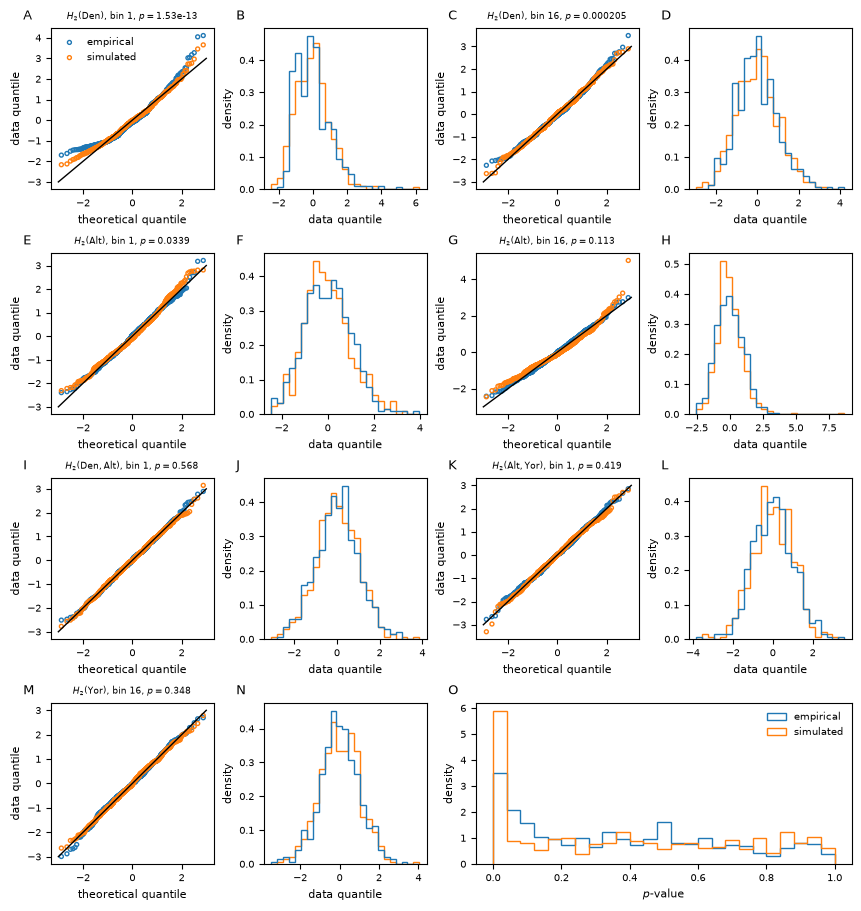

In [39]:
def qq_plot(ax, data, color, label=None):
    norm_data = np.sort((data - np.mean(data)) / np.std(data))
    quantiles = scipy.stats.norm.ppf(np.linspace(0, 1, len(norm_data)))
    ax.scatter(quantiles, norm_data, color=color, label=label, facecolor="none", s=8)
    ax.set_xlabel("theoretical quantile")
    ax.set_ylabel("data quantile")
    return norm_data


stat_names = h2py.utils._h2_names(len(pops))

fig, axs = plt.subplot_mosaic("ABCD;EFGH;IJKL;MNOO", figsize=(8.5, 9), layout="constrained")


def plot_panels(ax0, ax1, pop0, pop1, bin_idx):
    idx0 = pops.index(pop0)
    idx1 = pops.index(pop1)
    stat_idx = stat_names.index(f"H2_{idx0}_{idx1}")
    ax0.plot([-3, 3], [-3, 3], color="black", lw=1)
    empirical_distr = qq_plot(ax0, boot_samples[:, bin_idx, stat_idx], "tab:blue", label="empirical")
    sim_distr = qq_plot(ax0, sim_samples[:, bin_idx, stat_idx], "tab:orange", label="simulated")
    #axs["A"].legend(framealpha=0)
    if pop0 == pop1:
        label = "$H_2(\\text{" + pop1[:3] + "})$, bin " + str(bin_idx+1)
    else:
        label = "$H_2(\\text{" + pop0[:3] + "}, \\text{" + pop1[:3] + "})$, bin " + str(bin_idx+1)
    ax0.set_title(label + f", $p=${scipy.stats.shapiro(empirical_distr)[1]:.3}")
    ax1.hist([empirical_distr, sim_distr], bins=25, density=True, histtype="step")
    ax1.set_xlabel("data quantile")
    ax1.set_ylabel("density")
    return


plot_panels(axs["A"], axs["B"], "Denisova", "Denisova", 0)
axs["A"].legend(framealpha=0)
plot_panels(axs["C"], axs["D"], "Denisova", "Denisova", 15)
plot_panels(axs["E"], axs["F"], "Altai", "Altai", 0)
plot_panels(axs["G"], axs["H"], "Altai", "Altai", 15)
plot_panels(axs["I"], axs["J"], "Denisova", "Altai", 0)
plot_panels(axs["K"], axs["L"], "Altai", "Yoruba1", 0)
plot_panels(axs["M"], axs["N"], "Yoruba1", "Yoruba1", 15)

st, pv = scipy.stats.shapiro(boot_samples, axis=0)
sim_st, sim_pv = scipy.stats.shapiro(sim_samples, axis=0)

#for i in range(16):
    #axs["M"].scatter([i - 0.2] * 36, pv[i], color="tab:blue", facecolor="none")
axs["O"].hist(pv[:-1].flat, bins=np.linspace(0, 1, 26), histtype="step", density=True, label="empirical")
axs["O"].hist(sim_pv[:-1].flat, bins=np.linspace(0, 1, 26), histtype="step", density=True, label="simulated")
axs["O"].legend(framealpha=0)
axs["O"].set_xlabel("$p$-value")
axs["O"].set_ylabel("density")


for label, ax in axs.items():
    ax.text(0.0, 1.0, label, fontsize="large", va="bottom", transform=(
        ax.transAxes + mpl.transforms.ScaledTranslation(-20/72, 4/72, fig.dpi_scale_trans)))

plt.savefig("../../figures/bootstrap_normality.pdf")

In [30]:
pv

array([[1.53073934e-13, 5.68403200e-01, 7.89220194e-04, 3.37016541e-01,
        3.33557103e-01, 4.71390698e-01, 5.18652735e-02, 4.19025464e-01,
        3.38597304e-02, 7.89220194e-04, 3.37016541e-01, 3.33557103e-01,
        4.71390698e-01, 5.18652735e-02, 4.19025464e-01, 5.46337383e-01,
        9.61429391e-01, 4.94211012e-01, 5.19637703e-01, 3.24446822e-02,
        7.19759970e-01, 2.63892266e-03, 4.94211012e-01, 5.19637703e-01,
        3.24446822e-02, 7.19759970e-01, 9.29994081e-01, 1.98081662e-01,
        6.01799457e-01, 5.97623410e-02, 9.14679812e-02, 6.01799457e-01,
        5.97623410e-02, 6.23386476e-01, 5.97623410e-02, 2.45510515e-01],
       [7.37695508e-14, 8.54047917e-01, 6.76831129e-03, 6.12797185e-01,
        2.40819603e-01, 9.19786350e-01, 6.64081403e-02, 5.58276110e-01,
        1.23803971e-01, 6.76831129e-03, 6.12797185e-01, 2.40819603e-01,
        9.19786350e-01, 6.64081403e-02, 5.58276110e-01, 2.16321608e-01,
        7.44203283e-01, 3.59979800e-01, 6.31684036e-01, 1.01209

In [31]:
stat_names, pops

(['H2_0_0',
  'H2_0_1',
  'H2_0_2',
  'H2_0_3',
  'H2_0_4',
  'H2_0_5',
  'H2_0_6',
  'H2_0_7',
  'H2_1_1',
  'H2_1_2',
  'H2_1_3',
  'H2_1_4',
  'H2_1_5',
  'H2_1_6',
  'H2_1_7',
  'H2_2_2',
  'H2_2_3',
  'H2_2_4',
  'H2_2_5',
  'H2_2_6',
  'H2_2_7',
  'H2_3_3',
  'H2_3_4',
  'H2_3_5',
  'H2_3_6',
  'H2_3_7',
  'H2_4_4',
  'H2_4_5',
  'H2_4_6',
  'H2_4_7',
  'H2_5_5',
  'H2_5_6',
  'H2_5_7',
  'H2_6_6',
  'H2_6_7',
  'H2_7_7'],
 ['Denisova',
  'Altai',
  'Chagyrskaya',
  'Vindija',
  'UstIshim',
  'Loschbour',
  'Stuttgart',
  'Yoruba1'])